# Trabalho Unidade 3 — Processamento de Linguagem Natural (PLN)
## Notebook integrado: representações, clusterização, busca, classificação, sentimentos, NER e relações

**Objetivo:** executar e comparar técnicas de PLN no corpus de letras de músicas do grupo, produzindo tabelas, métricas e gráficos que apoiem as respostas das questões 1 a 6 do trabalho.

### Como executar
1. Coloque `dataset_musicas_preprocessado.json` na mesma pasta deste notebook ou, no Google Colab, faça upload quando solicitado.
2. Execute as células em ordem.
3. O notebook espera objetos JSON com os campos `titulo`, `artista`, `letra` e `metadados.genero_ranking`, conforme o notebook de classificação enviado. Há tratamento básico para campos ausentes.
4. **Word2Vec e BERT podem exigir mais tempo.** BERT baixa um modelo pré-treinado e pode consumir bastante memória. As opções podem ser desativadas na seção de configurações.

## 0. Configuração e dependências

In [ ]:
%pip -q install gensim transformers torch spacy seaborn
!python -m spacy download pt_core_news_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 61.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 94.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, re, json, warnings, unicodedata, subprocess, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    ConfusionMatrixDisplay, silhouette_score, davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Opções de execução de cada etapa.
EXECUTAR_WORD2VEC = True
EXECUTAR_BERT = True
EXECUTAR_SENTIMENTOS = True
EXECUTAR_NER_RELACOES = True

print("Ambiente pronto. Word2Vec:", EXECUTAR_WORD2VEC,
      "| BERT:", EXECUTAR_BERT,
      "| Sentimentos:", EXECUTAR_SENTIMENTOS,
      "| NER/relações:", EXECUTAR_NER_RELACOES)

Ambiente pronto. Word2Vec: True | BERT: True | Sentimentos: True | NER/relações: True


## 1. Carregar e preparar o corpus

In [ ]:
CAMINHO_DATASET = "dataset_musicas_preprocessado.json"

if not os.path.exists(CAMINHO_DATASET):
    try:
        from google.colab import files
        print("Selecione dataset_musicas_preprocessado.json")
        uploaded = files.upload()
        if uploaded:
            CAMINHO_DATASET = next(iter(uploaded))
    except Exception:
        pass

if not os.path.exists(CAMINHO_DATASET):
    raise FileNotFoundError(
        "Dataset não encontrado. Coloque dataset_musicas_preprocessado.json "
        "na pasta do notebook ou faça upload no Colab."
    )

with open(CAMINHO_DATASET, encoding="utf-8") as f:
    musicas_raw = json.load(f)

registros = []
for i, m in enumerate(musicas_raw):
    meta = m.get("metadados") or {}
    pre = m.get("preprocessamento") or {}
    letra = m.get("letra") or pre.get("texto_normalizado") or ""
    registros.append({
        "id": i,
        "titulo": m.get("titulo") or f"Música {i+1}",
        "artista": m.get("artista") or "Artista desconhecido",
        "genero": meta.get("genero_ranking") or m.get("genero") or None,
        "letra": str(letra).strip(),
        "texto_normalizado": str(pre.get("texto_normalizado") or letra).strip()
    })

df = pd.DataFrame(registros)
df = df.dropna(subset=["letra"]).copy()
df = df[df["letra"].str.len() > 0].copy()
df["genero"] = df["genero"].fillna("Gênero desconhecido").astype(str).str.strip()
df = df.drop_duplicates(subset=["titulo", "artista", "letra"]).reset_index(drop=True)
df["id"] = np.arange(len(df))

print("Músicas após preparação:", len(df))
print("Gêneros distintos:", df["genero"].nunique())
display(df[["titulo", "artista", "genero", "letra"]].head())
display(df["genero"].value_counts().rename_axis("gênero").to_frame("quantidade"))

Selecione dataset_musicas_preprocessado.json


Saving dataset_musicas_preprocessado.json to dataset_musicas_preprocessado.json
Músicas após preparação: 467
Gêneros distintos: 10


,titulo,artista,genero,letra
0,Peão Todo Tatuado (part. Jeninho),Mariana Fagundes,Sertanejo,Ela não vai pro rodeio pra ver montaria\nEla n...
1,Evidências,Chitãozinho & Xororó,Sertanejo,Quando eu digo que deixei de te amar\nÉ porque...
2,Te Esperando,Luan Santana,Sertanejo,Mesmo que você não caia na minha cantada\nMesm...
3,"Irmão da Lua, Amigo das Estrelas",Zezé Di Camargo & Luciano,Sertanejo,Cansei de me perder no caminho dessa madrugada...
4,Plano C,Zé Neto & Cristiano,Sertanejo,"Te trouxe aqui pra uma conversa séria\nPera, s..."


,quantidade
gênero,
MPB,47
Rock,47
Gospel,47
Forró,47
Rap,47
Pagode,47
Reggae,47
Sertanejo,46
Pop,46


### 1.1 Diagnóstico dos dados
A classificação supervisionada usa apenas as músicas com gênero conhecido. A análise exploratória e a busca usam todo o corpus.

Valores ausentes:


,ausentes
titulo,0
artista,0
genero,0
letra,0


Distribuição dos gêneros:


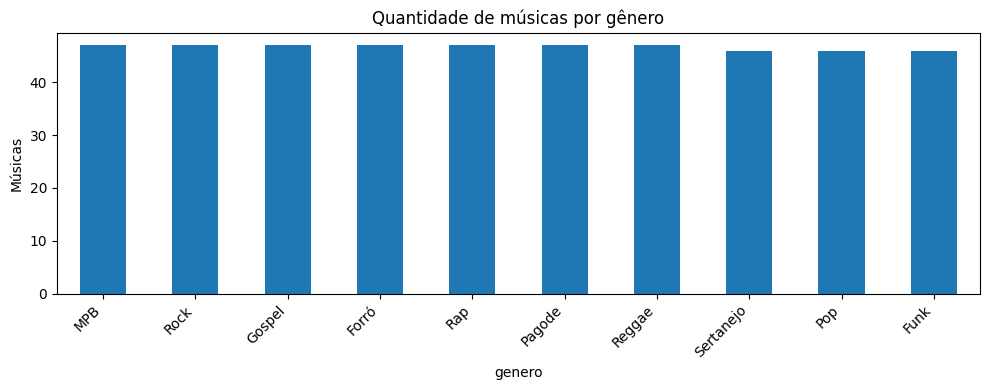

In [ ]:
print("Valores ausentes:")
display(df[["titulo", "artista", "genero", "letra"]].isna().sum().to_frame("ausentes"))
print("Distribuição dos gêneros:")
df["genero"].value_counts().plot(kind="bar", figsize=(10,4), title="Quantidade de músicas por gênero")
plt.ylabel("Músicas"); plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

## 2. Representações textuais: BoW e TF-IDF

In [ ]:
textos = df["letra"].fillna("").astype(str).tolist()

bow_vectorizer = CountVectorizer(
    lowercase=True, strip_accents="unicode", token_pattern=r"(?u)\b\w\w+\b",
    max_features=30000, ngram_range=(1, 2), min_df=1
)
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True, strip_accents="unicode", token_pattern=r"(?u)\b\w\w+\b",
    max_features=30000, ngram_range=(1, 2), min_df=1, max_df=0.98
)
X_bow = bow_vectorizer.fit_transform(textos)
X_tfidf = tfidf_vectorizer.fit_transform(textos)

print("BoW:", X_bow.shape, "| TF-IDF:", X_tfidf.shape)
print("Exemplo de vocabulário BoW:", bow_vectorizer.get_feature_names_out()[:20])

BoW: (467, 30000) | TF-IDF: (467, 30000)
Exemplo de vocabulário BoW: ['10' '157' '157 verdadeiro' '20' '20 20' '20 vision' '2t' '2t que' '38'
 '40' '40 graus' '50' 'aaaaah' 'aaaaah oh' 'aaaah' 'aaaah aaaaah' 'aah'
 'aba' 'aba yeroushalaim' 'abaixa']


## 3. Word2Vec: vetores médios por letra

In [ ]:
X_w2v = None
modelo_w2v = None
if EXECUTAR_WORD2VEC:
    try:
        from gensim.models import Word2Vec
        from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

        def tokens_pt(texto):
            texto = unicodedata.normalize("NFKD", str(texto).lower())
            texto = "".join(ch for ch in texto if not unicodedata.combining(ch))
            return re.findall(r"[a-zà-ÿ]+", texto)

        sentencas = [tokens_pt(t) for t in textos]
        sentencas = [s for s in sentencas if s]
        modelo_w2v = Word2Vec(
            sentences=sentencas, vector_size=100, window=5,
            min_count=1, workers=4, sg=1, seed=RANDOM_STATE, epochs=30
        )

        def vetor_medio_w2v(tokens, modelo, dim=100):
            conhecidos = [modelo.wv[t] for t in tokens if t in modelo.wv]
            return np.mean(conhecidos, axis=0) if conhecidos else np.zeros(dim)

        X_w2v = np.vstack([vetor_medio_w2v(tokens_pt(t), modelo_w2v) for t in textos])
        print("Matriz Word2Vec:", X_w2v.shape)
        print("Nota: o Word2Vec é treinado neste corpus; com poucos dados, os vetores podem ser instáveis.")
    except Exception as e:
        print("Erro ao executar o Word2Vec:", repr(e))
        X_w2v = None
else:
    print("Word2Vec desativado nas configurações.")

Matriz Word2Vec: (467, 100)
Nota: o Word2Vec é treinado neste corpus; com poucos dados, os vetores podem ser instáveis.


## 4. BERT: embeddings contextuais por letra

In [ ]:
X_bert = None
bert_model_name = "neuralmind/bert-base-portuguese-cased"
if EXECUTAR_BERT:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModel
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        tokenizer_bert = AutoTokenizer.from_pretrained(bert_model_name)
        model_bert = AutoModel.from_pretrained(bert_model_name).to(device)
        model_bert.eval()

        def embeddings_bert(lista_textos, batch_size=8, max_length=256):
            saidas = []
            with torch.no_grad():
                for inicio in range(0, len(lista_textos), batch_size):
                    lote = lista_textos[inicio:inicio+batch_size]
                    entradas = tokenizer_bert(
                        lote, padding=True, truncation=True, max_length=max_length,
                        return_tensors="pt"
                    ).to(device)
                    resultado = model_bert(**entradas).last_hidden_state
                    mascara = entradas["attention_mask"].unsqueeze(-1).expand(resultado.size()).float()
                    soma = (resultado * mascara).sum(1)
                    denominador = mascara.sum(1).clamp(min=1e-9)
                    saidas.append((soma / denominador).cpu().numpy())
            return np.vstack(saidas)

        # Para controlar custo, cada letra é truncada pelo tokenizer a max_length tokens.
        X_bert = embeddings_bert(textos)
        print("Matriz BERT:", X_bert.shape, "| dispositivo:", device)
    except Exception as e:
        print("Erro ao executar o BERT:", repr(e))
        X_bert = None
else:
    print("BERT desativado nas configurações.")

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Matriz BERT: (467, 768) | dispositivo: cpu


## 5. Questão 2 — clusterização, PCA e métricas

In [ ]:
representacoes = {"BoW": X_bow, "TF-IDF": X_tfidf}
if X_w2v is not None: representacoes["Word2Vec"] = X_w2v
if X_bert is not None: representacoes["BERT"] = X_bert

def clusterizar_e_avaliar(X, nome, ks=(2,3,4,5,8,10)):
    # Para matrizes esparsas, KMeans funciona diretamente; as métricas usam amostras se corpus grande.
    resultados = []
    n = X.shape[0]
    for k in ks:
        if k >= n or k < 2:
            continue
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = km.fit_predict(X)
        amostra = min(n, 2000)
        try:
            sil = silhouette_score(X, labels, metric="cosine", sample_size=amostra,
                                   random_state=RANDOM_STATE)
        except Exception:
            sil = np.nan
        try:
            # DB e CH requerem representação numérica; são calculados na matriz fornecida.
            X_eval = X.toarray() if hasattr(X, "toarray") else X
            if X_eval.shape[1] > 3000:
                X_eval = TruncatedSVD(n_components=min(100, X_eval.shape[1]-1),
                                      random_state=RANDOM_STATE).fit_transform(X)
            db = davies_bouldin_score(X_eval, labels)
            ch = calinski_harabasz_score(X_eval, labels)
        except Exception:
            db, ch = np.nan, np.nan
        resultados.append({"representação": nome, "k": k, "silhouette_coseno": sil,
                           "davies_bouldin": db, "calinski_harabasz": ch})
    return pd.DataFrame(resultados)

resultados_cluster = pd.concat(
    [clusterizar_e_avaliar(X, nome) for nome, X in representacoes.items()],
    ignore_index=True
)
display(resultados_cluster.sort_values(["representação", "k"]))

,representação,k,silhouette_coseno,davies_bouldin,calinski_harabasz
18,BERT,2,0.686564,0.793045,518.829224
19,BERT,3,0.450812,1.856653,294.269592
20,BERT,4,0.393425,2.157395,222.227722
21,BERT,5,0.228484,2.527475,174.328186
22,BERT,8,0.149296,2.439289,117.777756
23,BERT,10,0.122326,2.625317,96.005005
0,BoW,2,0.180726,2.069376,69.022516
1,BoW,3,-0.031802,1.864965,53.272247
2,BoW,4,-0.100026,2.000667,42.904897
3,BoW,5,-0.089793,1.994973,41.645174


**Como interpretar as métricas**
- *Silhouette* mais alto geralmente indica melhor separação e coesão; pode variar entre -1 e 1.
- *Davies–Bouldin* mais baixo costuma indicar clusters mais compactos e separados.
- *Calinski–Harabasz* mais alto costuma indicar grupos mais separados em relação à dispersão interna.
- Os gêneros conhecidos são uma referência para interpretação, não rótulos usados pelo K-Means.

Melhor k por silhouette: {'BoW': 2, 'TF-IDF': 2, 'Word2Vec': 2, 'BERT': 2}


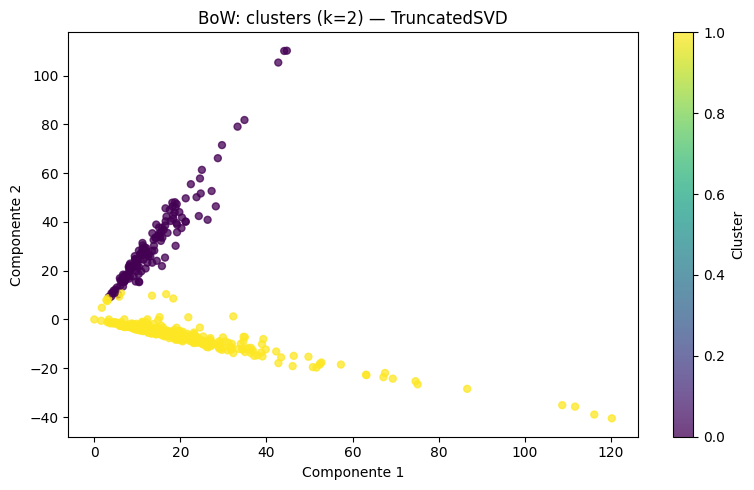

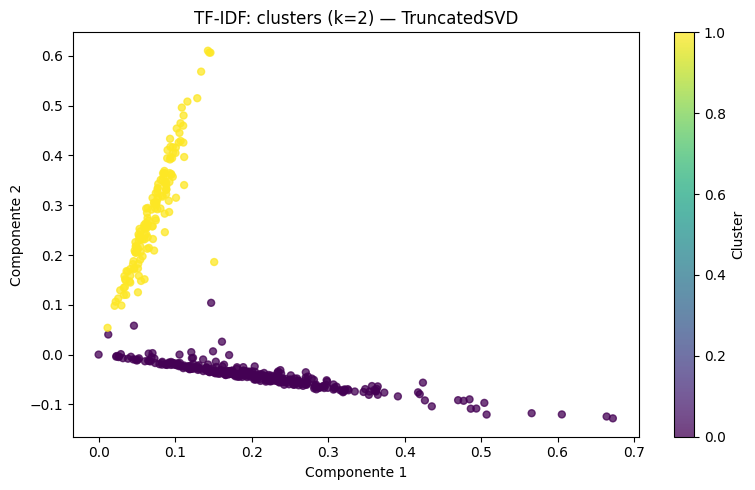

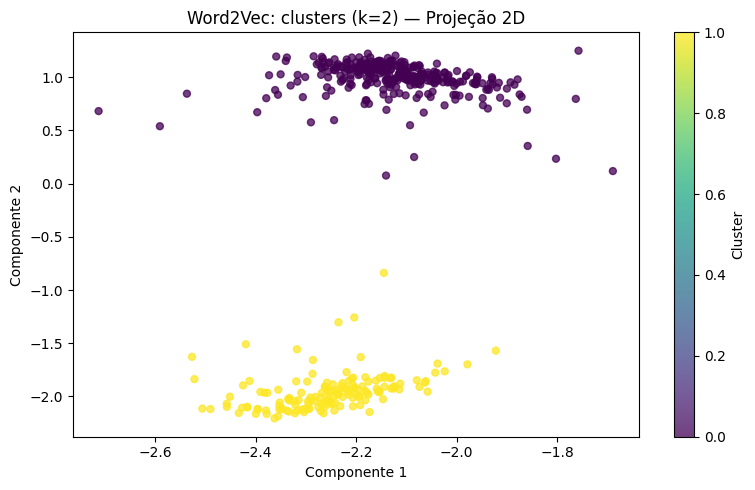

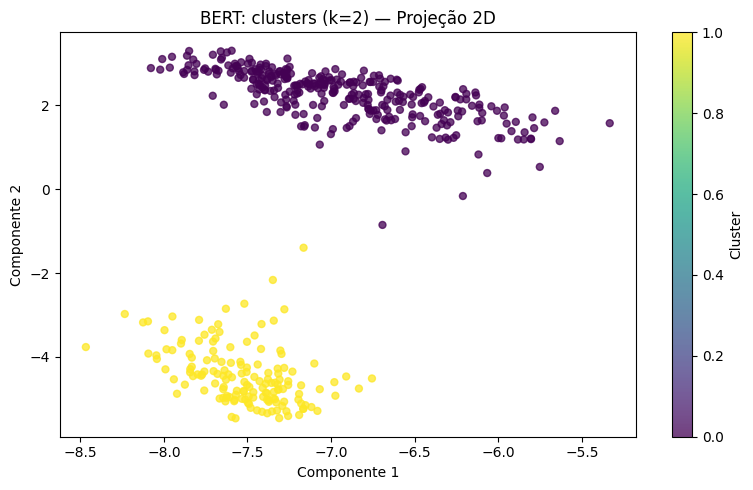

In [ ]:
# Escolha automaticamente o k com maior silhouette para cada representação, se a métrica existir.
melhores_k = {}
for nome in representacoes:
    sub = resultados_cluster[resultados_cluster["representação"] == nome].dropna(subset=["silhouette_coseno"])
    if len(sub):
        melhores_k[nome] = int(sub.loc[sub["silhouette_coseno"].idxmax(), "k"])
print("Melhor k por silhouette:", melhores_k)

def plot_pca_clusters(X, nome, k=None):
    if k is None: k = melhores_k.get(nome, 5)
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X)
    if hasattr(X, "toarray"):
        X_plot = TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
        metodo = "TruncatedSVD"
    else:
        X_plot = X if X.shape[1] <= 2 else TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
        metodo = "Projeção 2D"
    plt.figure(figsize=(8,5))
    scatter = plt.scatter(X_plot[:,0], X_plot[:,1], c=labels, s=25, alpha=.75)
    plt.title(f"{nome}: clusters (k={k}) — {metodo}")
    plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
    plt.colorbar(scatter, label="Cluster"); plt.tight_layout(); plt.show()
    return labels

labels_cluster = {}
for nome, X in representacoes.items():
    labels_cluster[nome] = plot_pca_clusters(X, nome)

In [ ]:
# Inspecionar termos/documentos representativos dos clusters.
def inspecionar_clusters(nome, X, labels, n_exemplos=3):
    print("\n###", nome)
    for c in sorted(np.unique(labels)):
        inds = np.where(labels == c)[0]
        print(f"\nCluster {c} — {len(inds)} músicas")
        if nome in ("BoW", "TF-IDF"):
            vec = bow_vectorizer if nome == "BoW" else tfidf_vectorizer
            mat = X[inds]
            medias = np.asarray(mat.mean(axis=0)).ravel()
            termos = vec.get_feature_names_out()
            top = np.argsort(medias)[-8:][::-1]
            print("Termos:", ", ".join(termos[top]))
        for ix in inds[:n_exemplos]:
            print(f"- {df.iloc[ix]['titulo']} — {df.iloc[ix]['artista']} [{df.iloc[ix]['genero']}]")
for nome, X in representacoes.items():
    inspecionar_clusters(nome, X, labels_cluster[nome])


### BoW

Cluster 0 — 141 músicas
Termos: you, the, and, me, it, to, my, in
- Training Season — Dua Lipa [Pop]
- Ordinary — Alex Warren [Pop]
- Die With A Smile (feat. Bruno Mars) — Lady Gaga [Pop]

Cluster 1 — 326 músicas
Termos: que, eu, de, nao, me, voce, pra, se
- Peão Todo Tatuado (part. Jeninho) — Mariana Fagundes [Sertanejo]
- Evidências — Chitãozinho & Xororó [Sertanejo]
- Te Esperando — Luan Santana [Sertanejo]

### TF-IDF

Cluster 0 — 318 músicas
Termos: que, eu, nao, de, voce, pra, te, se
- Peão Todo Tatuado (part. Jeninho) — Mariana Fagundes [Sertanejo]
- Evidências — Chitãozinho & Xororó [Sertanejo]
- Te Esperando — Luan Santana [Sertanejo]

Cluster 1 — 149 músicas
Termos: you, the, and, it, my, to, in, that
- Training Season — Dua Lipa [Pop]
- Ordinary — Alex Warren [Pop]
- Die With A Smile (feat. Bruno Mars) — Lady Gaga [Pop]

### Word2Vec

Cluster 0 — 316 músicas
- Peão Todo Tatuado (part. Jeninho) — Mariana Fagundes [Sertanejo]
- Evidências — Chitãozinho & Xororó [Sert

## 6. Questão 3 — busca e recomendação top-3/top-5

In [ ]:
def representar_consulta(consulta, nome):
    if nome == "BoW": return bow_vectorizer.transform([consulta])
    if nome == "TF-IDF": return tfidf_vectorizer.transform([consulta])
    if nome == "Word2Vec":
        return vetor_medio_w2v(tokens_pt(consulta), modelo_w2v).reshape(1, -1)
    if nome == "BERT":
        return embeddings_bert([consulta])
    raise ValueError(nome)

def buscar(consulta, nome, k=5):
    X = representacoes[nome]
    q = representar_consulta(consulta, nome)
    sims = cosine_similarity(q, X).ravel()
    ordem = np.argsort(sims)[::-1][:k]
    return pd.DataFrame({
        "posição": np.arange(1, len(ordem)+1),
        "similaridade": sims[ordem],
        "titulo": df.iloc[ordem]["titulo"].values,
        "artista": df.iloc[ordem]["artista"].values,
        "gênero": df.iloc[ordem]["genero"].values,
        "trecho": df.iloc[ordem]["letra"].str.replace("\n", " ", regex=False).str.slice(0, 220).values
    })

CONSULTAS = [
    "saudade de um amor que acabou",
    "dançar na festa com os amigos",
    "fé em Deus e esperança",
]
for consulta in CONSULTAS:
    print("\nCONSULTA:", consulta)
    for nome in representacoes:
        print("\nRepresentação:", nome, "— TOP 5")
        display(buscar(consulta, nome, k=5))


CONSULTA: saudade de um amor que acabou

Representação: BoW — TOP 5


,posição,similaridade,titulo,artista,gênero,trecho
0,1,0.420672,Flor E O Beija-Flor (part. Marília Mendonça),Henrique & Juliano,Sertanejo,Essa é uma velha história De uma flor e um bei...
1,2,0.346511,COMO É QUE FALA DE AMOR?,Gustavo Mioto,Sertanejo,Se te falaram que estranho é ofensa Que o sert...
2,3,0.332274,Seja Para Mim,Maneva,Reggae,Seja para mim o que você quiser Contanto que s...
3,4,0.330975,La Mour (Agamenon),Francis Lopes,Forró,Se eu não voltar pra casa Eu não posso viver A...
4,5,0.308498,É Tarde Demais,Raça Negra,Pagode,Olha só você Depois de me perder Veja só você ...



Representação: TF-IDF — TOP 5


,posição,similaridade,titulo,artista,gênero,trecho
0,1,0.166555,Seja Para Mim,Maneva,Reggae,Seja para mim o que você quiser Contanto que s...
1,2,0.154797,Flor E O Beija-Flor (part. Marília Mendonça),Henrique & Juliano,Sertanejo,Essa é uma velha história De uma flor e um bei...
2,3,0.149013,La Mour (Agamenon),Francis Lopes,Forró,Se eu não voltar pra casa Eu não posso viver A...
3,4,0.117731,Defeito Meu,Belo,Pagode,É um defeito meu Querer você assim de qualquer...
4,5,0.111636,É Tarde Demais,Raça Negra,Pagode,Olha só você Depois de me perder Veja só você ...



Representação: Word2Vec — TOP 5


...

,posição,similaridade,titulo,artista,gênero,trecho
0,1,0.141948,A Alma Abatida - 193,Harpa Cristã,Gospel,"Se tu, minh'alma, a Deus suplicas E não recebe..."
1,2,0.077867,Selado Na Luz,Gilson em Louvor,Reggae,Que toda língua que pronunciar o meu nome com ...
2,3,0.076691,Toda Bíblia É Comunicação,Padre Zezinho,Gospel,"Toda bíblia é comunicação De um Deus amor, de ..."
3,4,0.073341,Clareou,Xande de Pilares,Pagode,"(Deus é quem sabe) (Tá escrito, vai!) (Clareo..."
4,5,0.072028,"Vida Loka, Pt. 1",Racionais MC's,Rap,"Vagabunda, queria atacar do malucão Usou meu n..."



Representação: Word2Vec — TOP 5


,posição,similaridade,titulo,artista,gênero,trecho
0,1,0.839567,A Alma Abatida - 193,Harpa Cristã,Gospel,"Se tu, minh'alma, a Deus suplicas E não recebe..."
1,2,0.825616,Conversão - 15,Harpa Cristã,Gospel,"Oh! Quão cego andei e perdido vaguei Longe, lo..."
2,3,0.823875,Oração de São Francisco,Fagner,MPB,"Senhor, fazei-me instrumento de vossa paz Onde..."
3,4,0.823385,Agindo Diferente,Eliã Oliveira,Gospel,O rei da Síria sitiou a Samaria Pois o que ele...
4,5,0.822549,Selado Na Luz,Gilson em Louvor,Reggae,Que toda língua que pronunciar o meu nome com ...



Representação: BERT — TOP 5


,posição,similaridade,titulo,artista,gênero,trecho
0,1,0.592099,Toda Bíblia É Comunicação,Padre Zezinho,Gospel,"Toda bíblia é comunicação De um Deus amor, de ..."
1,2,0.560299,Ó Desce Fogo Santo - 5,Harpa Cristã,Gospel,"Espírito, alma e corpo Oferto a Ti, Senhor Com..."
2,3,0.556709,Porque Ele Vive - 545,Harpa Cristã,Gospel,Deus enviou Seu Filho amado Pra me salvar e pe...
3,4,0.542329,Campeões da luz - 305,Harpa Cristã,Gospel,"Soldados somos de Jesus E campeões do bem, da ..."
4,5,0.540983,Firme nas Promessas - 107,Harpa Cristã,Gospel,Firme nas promessas do meu Salvador Cantarei l...


**Leitura dos resultados:** para cada consulta, os top-3 e top-5 são comparados entre as representações. A similaridade alta não garante relevância; a avaliação de relevância está no README.

## 7. Questão 4 — classificação comparativa

Registros rotulados: 467 | gêneros: 10


,quantidade
genero,
MPB,47
Rock,47
Gospel,47
Forró,47
Rap,47
Pagode,47
Reggae,47
Sertanejo,46
Pop,46



 BoW
              precision    recall  f1-score   support

       Forró       0.36      0.40      0.38        10
        Funk       0.44      0.78      0.56         9
      Gospel       0.75      1.00      0.86         9
         MPB       0.43      0.30      0.35        10
      Pagode       0.43      0.33      0.38         9
         Pop       0.50      0.33      0.40         9
         Rap       0.60      0.60      0.60        10
      Reggae       1.00      0.22      0.36         9
        Rock       0.33      0.50      0.40        10
   Sertanejo       0.12      0.11      0.12         9

    accuracy                           0.46        94
   macro avg       0.50      0.46      0.44        94
weighted avg       0.49      0.46      0.44        94



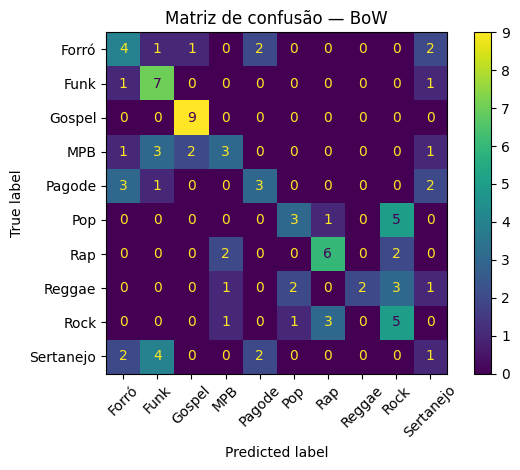


 TF-IDF
              precision    recall  f1-score   support

       Forró       0.33      0.20      0.25        10
        Funk       0.29      0.67      0.40         9
      Gospel       0.69      1.00      0.82         9
         MPB       0.00      0.00      0.00        10
      Pagode       0.27      0.33      0.30         9
         Pop       0.25      0.33      0.29         9
         Rap       1.00      0.10      0.18        10
      Reggae       0.75      0.33      0.46         9
        Rock       0.27      0.40      0.32        10
   Sertanejo       0.38      0.33      0.35         9

    accuracy                           0.36        94
   macro avg       0.42      0.37      0.34        94
weighted avg       0.42      0.36      0.33        94



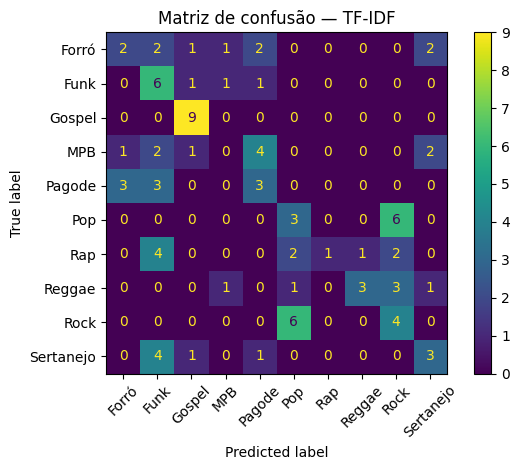


 Word2Vec
              precision    recall  f1-score   support

       Forró       0.30      0.30      0.30        10
        Funk       0.47      0.89      0.62         9
      Gospel       0.90      1.00      0.95         9
         MPB       0.20      0.10      0.13        10
      Pagode       0.31      0.44      0.36         9
         Pop       0.20      0.33      0.25         9
         Rap       0.40      0.20      0.27        10
      Reggae       0.00      0.00      0.00         9
        Rock       0.36      0.40      0.38        10
   Sertanejo       0.12      0.11      0.12         9

    accuracy                           0.37        94
   macro avg       0.33      0.38      0.34        94
weighted avg       0.33      0.37      0.33        94



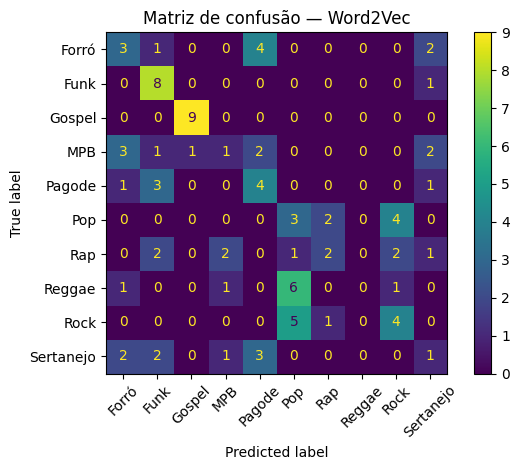


 BERT
              precision    recall  f1-score   support

       Forró       0.50      0.40      0.44        10
        Funk       0.67      0.89      0.76         9
      Gospel       0.89      0.89      0.89         9
         MPB       0.43      0.30      0.35        10
      Pagode       0.33      0.44      0.38         9
         Pop       0.36      0.44      0.40         9
         Rap       0.56      0.50      0.53        10
      Reggae       0.25      0.11      0.15         9
        Rock       0.42      0.50      0.45        10
   Sertanejo       0.30      0.33      0.32         9

    accuracy                           0.48        94
   macro avg       0.47      0.48      0.47        94
weighted avg       0.47      0.48      0.47        94



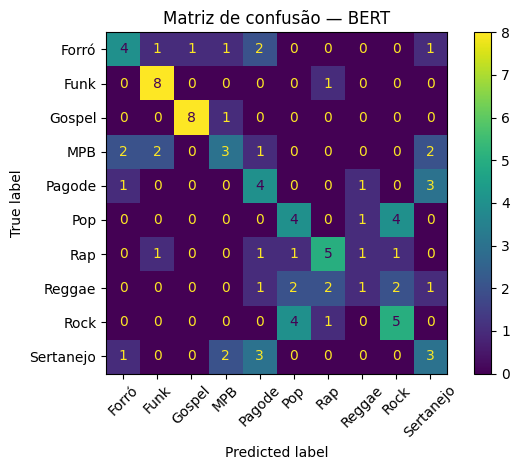

,representação,acurácia,precisão_macro,revocação_macro,F1_macro
3,BERT,0.478723,0.470332,0.481111,0.467963
0,BoW,0.457447,0.496661,0.457778,0.440732
2,Word2Vec,0.372340,0.326692,0.377778,0.337499
1,TF-IDF,0.361702,0.422575,0.370000,0.337019


In [ ]:
# A classificação usa somente linhas com rótulos conhecidos e ao menos 2 exemplos por classe.
df_clf = df[(df["genero"] != "Gênero desconhecido") & (df["genero"].str.len() > 0)].copy()
contagens = df_clf["genero"].value_counts()
classes_validas = contagens[contagens >= 2].index
df_clf = df_clf[df_clf["genero"].isin(classes_validas)].reset_index(drop=True)

print("Registros rotulados:", len(df_clf), "| gêneros:", df_clf["genero"].nunique())
display(df_clf["genero"].value_counts().to_frame("quantidade"))

if df_clf["genero"].nunique() < 2:
    print("Não há classes suficientes para classificação supervisionada.")
else:
    indices = df_clf.index.to_numpy()
    X_train_idx, X_test_idx = train_test_split(
        indices, test_size=0.2, random_state=RANDOM_STATE,
        stratify=df_clf["genero"]
    )
    y_train = df_clf.loc[X_train_idx, "genero"].to_numpy()
    y_test = df_clf.loc[X_test_idx, "genero"].to_numpy()

    def matriz_subset(nome, idx):
        X = representacoes[nome]
        # Representações foram geradas a partir do df principal. Alinhar via id original.
        orig_indices = df_clf.loc[idx, "id"].to_numpy()
        return X[orig_indices]

    resultados_classificacao = []
    modelos_clf = {}
    for nome in representacoes:
        Xtr = matriz_subset(nome, X_train_idx)
        Xte = matriz_subset(nome, X_test_idx)
        modelo = LogisticRegression(max_iter=1500, class_weight="balanced",
                                    random_state=RANDOM_STATE)
        modelo.fit(Xtr, y_train)
        pred = modelo.predict(Xte)
        p, r, f1, _ = precision_recall_fscore_support(
            y_test, pred, average="macro", zero_division=0
        )
        resultados_classificacao.append({
            "representação": nome, "acurácia": accuracy_score(y_test, pred),
            "precisão_macro": p, "revocação_macro": r, "F1_macro": f1
        })
        modelos_clf[nome] = modelo
        print("\n", nome)
        print(classification_report(y_test, pred, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45)
        plt.title(f"Matriz de confusão — {nome}")
        plt.tight_layout(); plt.show()

    df_resultados_clf = pd.DataFrame(resultados_classificacao).sort_values("F1_macro", ascending=False)
    display(df_resultados_clf)

**Cuidados para a classificação:** a comparação usa a mesma divisão treino/teste e o mesmo classificador para cada representação. Word2Vec treinado no próprio corpus é uma linha de base simples; não equivale a um modelo pré-treinado. A acurácia pode ser enganosa com gêneros desbalanceados, por isso observe F1 macro, revocação por classe e matriz de confusão.

In [ ]:
# Exemplo de classificação de textos novos com o melhor modelo pela métrica F1 macro.
if "df_resultados_clf" in globals() and len(df_resultados_clf):
    melhor_nome = df_resultados_clf.iloc[0]["representação"]
    modelo = modelos_clf[melhor_nome]
    novos_textos = [
        "Deus me dá força e esperança, eu sigo com fé no coração.",
        "Saudade da pessoa amada, lembro do beijo e do nosso amor.",
        "A festa começou, vamos dançar e cantar até amanhecer."
    ]
    X_novos = []
    for t in novos_textos:
        if melhor_nome == "BoW": X_novos.append(bow_vectorizer.transform([t]))
        elif melhor_nome == "TF-IDF": X_novos.append(tfidf_vectorizer.transform([t]))
        elif melhor_nome == "Word2Vec": X_novos.append(vetor_medio_w2v(tokens_pt(t), modelo_w2v).reshape(1,-1))
        elif melhor_nome == "BERT": X_novos.append(embeddings_bert([t]))
    preds = [modelo.predict(x)[0] for x in X_novos]
    display(pd.DataFrame({"texto": novos_textos, "gênero_previsto": preds,
                          "representação": melhor_nome}))

,texto,gênero_previsto,representação
0,"Deus me dá força e esperança, eu sigo com fé n...",Rap,BERT
1,"Saudade da pessoa amada, lembro do beijo e do ...",Forró,BERT
2,"A festa começou, vamos dançar e cantar até ama...",Forró,BERT


## 8. Questão 5A — análise de sentimentos (modelo pré-treinado)

In [ ]:
!pip install pysentimiento

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 15.9 MB/s eta 0:00:00


In [ ]:
sentimentos_df = None
if EXECUTAR_SENTIMENTOS:
    try:
        # Pysentimiento fornece um analisador de sentimento para português.
        from pysentimiento import create_analyzer
        analisador_sentimento = create_analyzer(task="sentiment", lang="pt")
        amostra_sent = df.copy()
        resultados_sent = []
        for _, row in amostra_sent.iterrows():
            # Limita o texto para reduzir custo. Resultado é estimativa de modelo, não verdade absoluta.
            trecho = row["letra"][:1500]
            res = analisador_sentimento.predict(trecho)
            resultados_sent.append({
                "titulo": row["titulo"], "artista": row["artista"], "gênero": row["genero"],
                "sentimento": res.output,
                "probabilidades": str(getattr(res, "probas", {})),
                "trecho_analisado_caracteres": len(trecho)
            })
        sentimentos_df = pd.DataFrame(resultados_sent)
        display(sentimentos_df.head(20))
        display(sentimentos_df["sentimento"].value_counts().to_frame("quantidade"))
    except Exception as e:
        print("Erro ao executar a análise de sentimentos:", repr(e))
else:
    print("Análise de sentimentos desativada.")

config.json:   0%|          | 0.00/952 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/562 [00:00<?, ?B/s]

...

bpe.codes:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

,titulo,artista,gênero,sentimento,probabilidades,trecho_analisado_caracteres
0,Peão Todo Tatuado (part. Jeninho),Mariana Fagundes,Sertanejo,NEU,"{'NEG': 0.07704918086528778, 'NEU': 0.57755249...",1074
1,Evidências,Chitãozinho & Xororó,Sertanejo,NEU,"{'NEG': 0.13682834804058075, 'NEU': 0.72104126...",1013
2,Te Esperando,Luan Santana,Sertanejo,NEU,"{'NEG': 0.11231620609760284, 'NEU': 0.80783158...",1500
3,"Irmão da Lua, Amigo das Estrelas",Zezé Di Camargo & Luciano,Sertanejo,NEU,"{'NEG': 0.24369998276233673, 'NEU': 0.59812277...",1436
4,Plano C,Zé Neto & Cristiano,Sertanejo,NEU,"{'NEG': 0.10145628452301025, 'NEU': 0.76904344...",1107
5,Caso Indefinido,Cristiano Araújo,Sertanejo,NEU,"{'NEG': 0.08955341577529907, 'NEU': 0.78918802...",1246
6,Decida,Milionário & José Rico,Sertanejo,NEU,"{'NEG': 0.2139970362186432, 'NEU': 0.698498189...",1500
7,Tocando Em Frente,Almir Sater,Sertanejo,NEU,"{'NEG': 0.05279959738254547, 'NEU': 0.65292698...",1197
8,Foi por Conveniência,Marília Mendonça,Sertanejo,NEU,"{'NEG': 0.175336092710495, 'NEU': 0.7078405618...",1096
9,Chuva de Arroz,Luan Santana,Sertanejo,NEU,"{'NEG': 0.07333632558584213, 'NEU': 0.79234242...",1063


,quantidade
sentimento,
NEU,417
POS,42
NEG,8


**Interpretação dos sentimentos:** letras podem conter ironia, metáforas, narradores e emoções misturadas; o resultado automático é uma estimativa do modelo.

## 9. Questão 5B — reconhecimento de entidades nomeadas (NER) e relações

In [ ]:
entidades_df = None
relacoes_df = None
if EXECUTAR_NER_RELACOES:
    try:
        import spacy
        try:
            nlp = spacy.load("pt_core_news_sm")
        except OSError:
            print("Modelo spaCy pt_core_news_sm ausente. Em Colab, execute: !python -m spacy download pt_core_news_sm")
            nlp = None

        if nlp is not None:
            # NER aplicado a uma amostra do corpus para limitar o tempo de execução.
            N_MUSICAS_NER = min(200, len(df))
            docs_ner = list(nlp.pipe(df.iloc[:N_MUSICAS_NER]["letra"].tolist(), batch_size=16))
            ent_rows = []
            for i, doc in enumerate(docs_ner):
                for ent in doc.ents:
                    ent_rows.append({
                        "titulo": df.iloc[i]["titulo"], "gênero": df.iloc[i]["genero"],
                        "entidade": ent.text, "categoria": ent.label_
                    })
            entidades_df = pd.DataFrame(ent_rows)
            print("Entidades encontradas:", len(entidades_df))
            if len(entidades_df):
                display(entidades_df.head(30))
                display(entidades_df.groupby(["categoria", "entidade"]).size()
                        .sort_values(ascending=False).head(25).to_frame("ocorrências"))

            def sintagma(token):
                return token.doc[min(t.i for t in token.subtree):max(t.i for t in token.subtree)+1].text

            def extrair_svo(texto):
                doc = nlp(texto)
                saida = []
                for verbo in doc:
                    if verbo.pos_ not in ("VERB", "AUX"):
                        continue
                    sujeitos = [t for t in verbo.children if t.dep_ in ("nsubj", "nsubj:pass", "csubj")]
                    objetos = [t for t in verbo.children if t.dep_ in ("obj", "dobj", "iobj", "obl", "attr", "oprd")]
                    for s in sujeitos:
                        for o in objetos:
                            saida.append({
                                "sujeito": sintagma(s), "relação": verbo.lemma_,
                                "objeto": sintagma(o), "verso": texto
                            })
                return saida

            # Cada linha da letra é tratada como verso/unidade para limitar relações espúrias.
            rel_rows = []
            for i, row in df.head(N_MUSICAS_NER).iterrows():
                for verso in str(row["letra"]).splitlines():
                    verso = verso.strip()
                    if len(verso) < 3:
                        continue
                    for rel in extrair_svo(verso):
                        rel.update({"titulo": row["titulo"], "gênero": row["genero"]})
                        rel_rows.append(rel)
            relacoes_df = pd.DataFrame(rel_rows)
            print("Relações extraídas por regras sintáticas:", len(relacoes_df))
            if len(relacoes_df):
                display(relacoes_df.head(30))
    except Exception as e:
        print("Erro ao executar NER/extração de relações:", repr(e))
else:
    print("NER e extração de relações desativados.")

Entidades encontradas: 6149


,titulo,gênero,entidade,categoria
0,Peão Todo Tatuado (part. Jeninho),Sertanejo,Sabe,PER
1,Peão Todo Tatuado (part. Jeninho),Sertanejo,Sabe,PER
2,Peão Todo Tatuado (part. Jeninho),Sertanejo,Peão,PER
3,Peão Todo Tatuado (part. Jeninho),Sertanejo,Beijo,LOC
4,Peão Todo Tatuado (part. Jeninho),Sertanejo,Peão,PER
5,Peão Todo Tatuado (part. Jeninho),Sertanejo,Beijo,LOC
6,Peão Todo Tatuado (part. Jeninho),Sertanejo,Peão,PER
7,Peão Todo Tatuado (part. Jeninho),Sertanejo,Sabe,PER
8,Peão Todo Tatuado (part. Jeninho),Sertanejo,Sabe,PER
9,Peão Todo Tatuado (part. Jeninho),Sertanejo,Ha-ha-ha\nPeão,PER


ocorrências
categoria entidade             
MISC      yeah               70
          Yeah               51
          I                  50
          Me                 40
PER       Pra                37
MISC      We                 33
          ooh                32
PER       Baby               29
MISC      Quero              28
          In                 26
LOC       Vou                26
MISC      Turn               26
PER       Tô                 25
ORG       Cause              24
MISC      Ooh                24
PER       Pai                23
          Hootie             22
MISC      For                22
          Cê                 20
          Just               19
LOC       go                 18
MISC      You're             17
          And I              17
PER       Just               16
MISC      When               16

Relações extraídas por regras sintáticas: 2498


,sujeito,relação,objeto,verso,titulo,gênero
0,ela,querer,que,Sabe o que que ela quer? Ha-ha-ha,Peão Todo Tatuado (part. Jeninho),Sertanejo
1,ela,querer,que,Sabe o que que ela quer? Ha-ha-ha,Peão Todo Tatuado (part. Jeninho),Sertanejo
2,eu,querer,te,É porque eu te quero,Evidências,Sertanejo
3,Eu,ter,medo de te dar meu coração,Eu tenho medo de te dar meu coração,Evidências,Sertanejo
4,eu,perder,te,Se eu te perder um dia,Evidências,Sertanejo
5,eu,perder,um dia,Se eu te perder um dia,Evidências,Sertanejo
6,Eu,querer,te,Eu te quero mais que tudo,Evidências,Sertanejo
7,Eu,entregar,a minha vida,Eu entrego a minha vida,Evidências,Sertanejo
8,você,fazer,o que quiser de mim,Pra você fazer o que quiser de mim,Evidências,Sertanejo
9,que,ter,saudade,"Diz que é verdade, que tem saudade",Evidências,Sertanejo


### Limitações de NER e extração de relações
- O modelo `pt_core_news_sm` tem um conjunto limitado de categorias e pode confundir palavras comuns com nomes próprios.
- A extração sujeito–verbo–objeto é baseada em regras sintáticas simples; relações expressas por preposições, elipses, pronomes, metáforas e versos fragmentados podem ser perdidas ou interpretadas incorretamente.

## 10. Exportar tabelas de resultados

In [ ]:
PASTA_SAIDA = "resultados_trabalho_unidade3"
os.makedirs(PASTA_SAIDA, exist_ok=True)

def salvar_csv(obj, nome):
    if isinstance(obj, pd.DataFrame) and len(obj):
        caminho = os.path.join(PASTA_SAIDA, nome)
        obj.to_csv(caminho, index=False, encoding="utf-8-sig")
        print("Salvo:", caminho)

salvar_csv(df, "corpus_preparado.csv")
salvar_csv(resultados_cluster, "metricas_clusterizacao.csv")
if "df_resultados_clf" in globals(): salvar_csv(df_resultados_clf, "metricas_classificacao.csv")
if "sentimentos_df" in globals(): salvar_csv(sentimentos_df, "analise_sentimentos.csv")
if "entidades_df" in globals(): salvar_csv(entidades_df, "entidades_nomeadas.csv")
if "relacoes_df" in globals(): salvar_csv(relacoes_df, "relacoes_extraidas.csv")
print("Arquivos disponíveis na pasta:", PASTA_SAIDA)

Salvo: resultados_trabalho_unidade3/corpus_preparado.csv
Salvo: resultados_trabalho_unidade3/metricas_clusterizacao.csv
Salvo: resultados_trabalho_unidade3/metricas_classificacao.csv
Salvo: resultados_trabalho_unidade3/analise_sentimentos.csv
Salvo: resultados_trabalho_unidade3/entidades_nomeadas.csv
Salvo: resultados_trabalho_unidade3/relacoes_extraidas.csv
Arquivos disponíveis na pasta: resultados_trabalho_unidade3


In [ ]:
# Amostra 5 músicas aleatórias por cluster (k=2) para leitura qualitativa
for nome, lab in labels_cluster.items():
    for c in sorted(set(lab)):
        print(f"\n### {nome} — cluster {c}")
        idx = np.random.RandomState(42).choice(np.where(lab == c)[0], 5, replace=False)
        for ix in idx:
            print("-", df.iloc[ix]["titulo"], "|", df.iloc[ix]["genero"], "|",
                  df.iloc[ix]["letra"][:150].replace("\n", " "))


### BoW — cluster 0
- Sunday Morning | Rock | Yeah  Sunday morning, rain is falling Steal some covers, share some skin (I like that) Clouds are shrouding us in moments unforgettable You twist to f
- Congratulations (feat. Quavo) | Rap | [Post Malone] Yeah, yeah Yeah  My mama called: Seen you on TV, son Said shit done changed ever since we was on I dreamed it all ever since I was young
- Ain't In LA | Pop | Uh, back it up, subwoofers in the trunk and the— Uh, gemstones in the teeth go dumb and the— Uh, light the cigarette with the propane Uh, Honda Civic 
- Do I Wanna Know? | Rock | Have you got colour in your cheeks? Do you ever get that fear that you can't shift The type that sticks around like summat in your teeth? Are there so
- Him & I (feat. Halsey) | Rap | Cross my heart, hope to die To my lover, I'd never lie He said, be true, I swear, I'll try In the end, it's him and I  He's out his head, I'm out my m

### BoW — cluster 1
- Anjo Querubim | Forró | Fiz você pra mim, meu brinqu